# Lab 4 : PCA

## G3 SDI - Machine Learning

In this lab, we are going to study the most fundamental dimensionality reduction method : PCA. More precisely, we are going to apply it to the *Olivetti* dataset, which contains images of faces.

### Instructions
* Rename your notebook with your surnames as `lab4_Name1_Name2.ipynb`, and include your names in the notebook.
* Your code, and its output, must be commented !
* Please upload your notebook on Moodle in the dedicated section before the deadline.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Report written by [name1], [name2], date.
</div>

In [1]:
# Import usual libraries
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# Import the dataset
from sklearn.datasets import fetch_olivetti_faces

data = fetch_olivetti_faces()

**Q1.** What is this dataset about ? How many examples do we have ? How many features ?

Display the first 50 images from the dataset. Comment.

(400, 4096)
(400, 64, 64)
(400,)


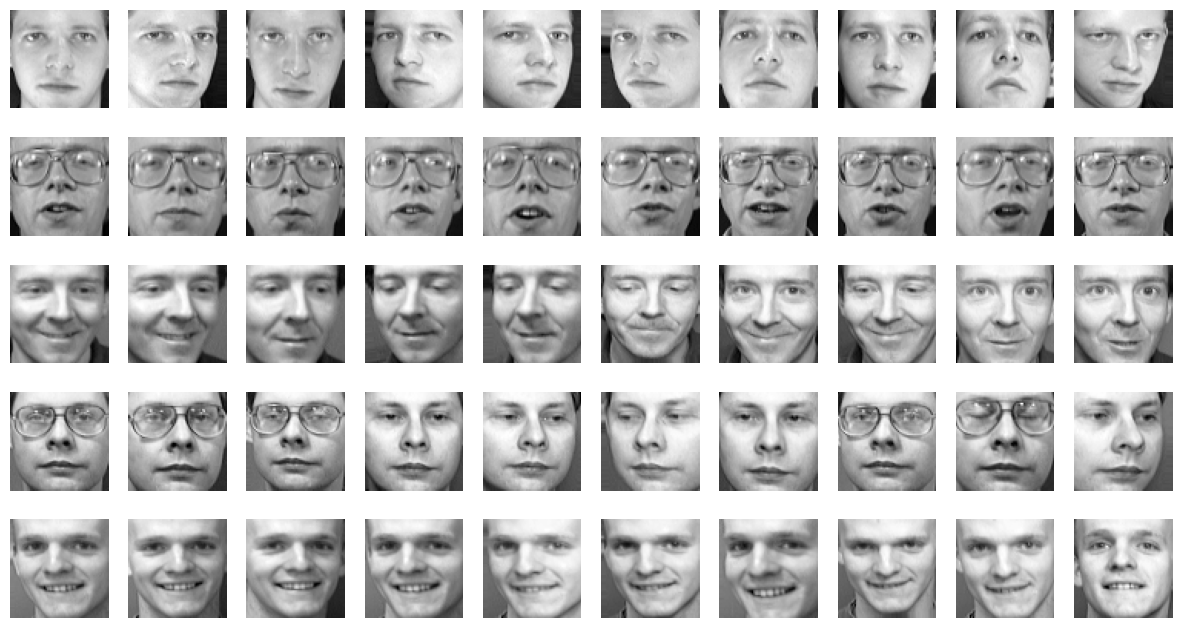

In [ ]:
print(data.data.shape)
print(data.images.shape)
print(data.target.shape)

images = data.images

#display the first 50 images
fig, ax = plt.subplots(5, 10, figsize=(15, 8))
for i in range(5):
    for j in range(10):
        ax[i, j].imshow(images[i * 10 + j], cmap='gray')
        ax[i, j].axis('off')


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
There are 64*64 features = 4096
</div>

**Q2**. Now apply PCA to the dataset, using scikit-learn (documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)).

Plot the cumulative explained variance. How many components do we need to explain 95% of the variance ?

Number of components to reach 95% variance: 123


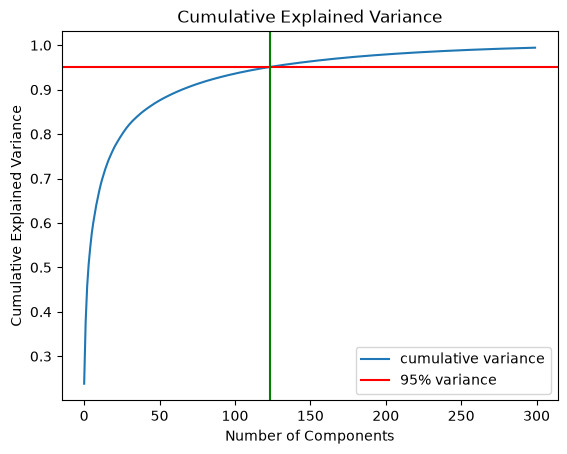

In [ ]:
from sklearn.decomposition import PCA

X = images.reshape((400, 4096))
n_components = 300
pca = PCA(n_components=n_components)
pca.fit(X)
# print(pca.explained_variance_ratio_)
variance = (pca.explained_variance_ratio_)
cum_variance = []
cum_var = 0
count = 0
for num, var in enumerate(variance):
    cum_var += var
    cum_variance.append(cum_var)
    if cum_var >= 0.95 and count == 0:
        print(f"Number of components to reach 95% variance: {num + 1}")
        count += 1
components = np.arange(n_components)


plt.plot(components, cum_variance, label = "cumulative variance")
plt.axhline(y=0.95, color="r", linestyle="-", label ="95% variance")
plt.axvline(x=123, color="g", linestyle="-")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()


Visage moyen :

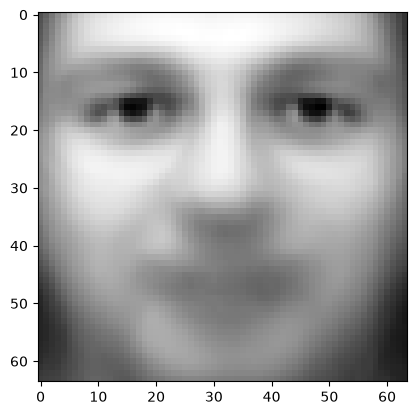

In [5]:
#mean face :
mean_face = pca.mean_.reshape((64, 64))
plt.imshow(mean_face, cmap='gray')

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
We need 123 components to explain 95% of the variance.
</div>

**Q3.** Retrieve the principal components. These are the so-called *eigenfaces*. Display the first 40, and comment : what do the main components seem to capture ? What about later components ?

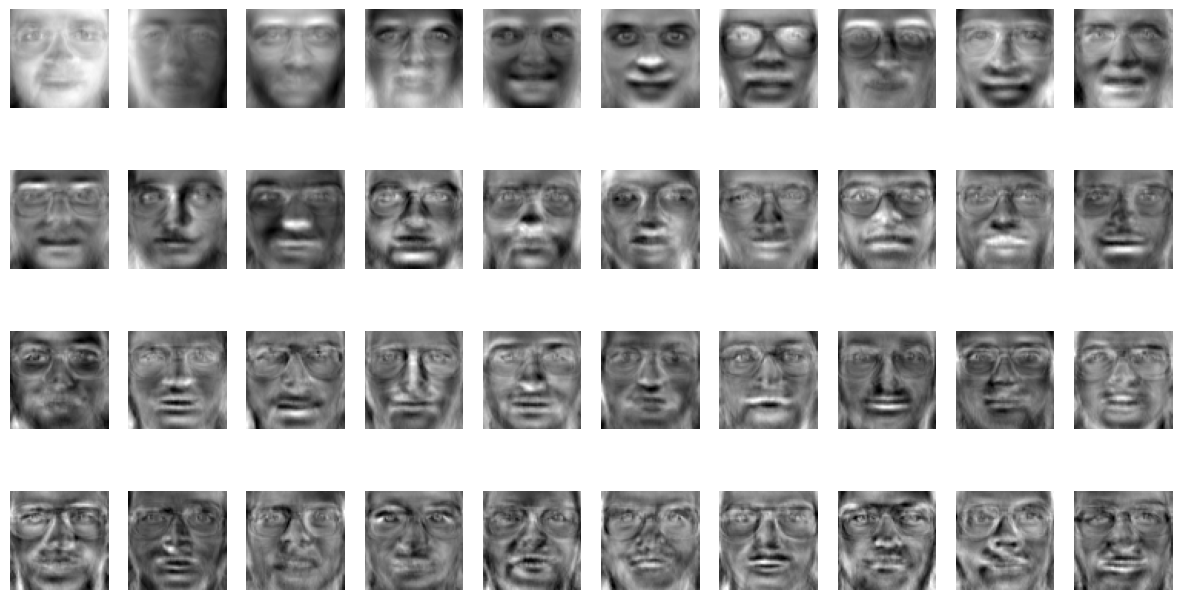

In [ ]:
Z = pca.components_.reshape((300, 64, 64))

fig, ax = plt.subplots(4, 10, figsize=(15, 8))
for i in range(4):
    for j in range(10):
        ax[i, j].imshow(Z[i * 10 + j], cmap="gray")
        ax[i, j].axis("off")


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Les premières composantes principales semblent correspondre aux caractéristiques principales qu'un humain utilise pour différencier un visage d'un autre. La première semble correspondre à la forme générale du visage, tandis que la deuxième semble correspondre aux contours extérieurs du visage. Les composantes supérieures caractérisent des aspects de plus en plus spécifiques du visage (bout du nez, sourcils, etc...).
</div>

**Q4.** The *Olivetti* dataset contains a target variable, which correspond to the ID of the person in the photo (there are 40 distinct persons).

Compare the cross-validated performance (e.g., 5-fold) of logistic regression on the original dataset vs. on the representation induced by PCA using the first 50 components. Be careful to *stratify* the test set. Comment. You may also take the execution time in consideration in your reply.

In [ ]:
import time
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

model = make_pipeline(LogisticRegression(max_iter=1000))
model_pca = make_pipeline(PCA(n_components=50), LogisticRegression(max_iter=1000)
)

t = time.time()
cv_score = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")
t1 = time.time() - t

t = time.time()
cv_score_pca = cross_val_score(model_pca, X_train, y_train, cv=skf, scoring="accuracy")
t2 = time.time() - t

print(f"No PCA : acc={cv_score.mean():.4f} ± {cv_score.std():.4f}  time={t1:.2f}s")
print(
    f"PCA 50 : acc={cv_score_pca.mean():.4f} ± {cv_score_pca.std():.4f}  time={t2:.2f}s"
)

# Final check on the held-out test set
for name, m in [("No PCA", model), ("PCA 50", model_pca)]:
    m.fit(X_train, y_train)
    print(name, "test acc:", m.score(X_test, y_test))


No PCA : acc=0.9594 ± 0.0290  time=40.22s
PCA 50 : acc=0.9563 ± 0.0250  time=0.62s
No PCA test acc: 0.975
PCA 50 test acc: 0.9625


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
The cross-validated performance of logistic regression on the original dataset is 95,9%, while on the representation induced by PCA using the first 50 components is 95,6%.  So there is no improvement but the execution time is reduced by a factor of 100.
</div>

In [ ]:
#Recherche du meilleur compromis performance/temps d'éxécution en faisant varier le nombre de composantes principales.

#on refactorise la pipeline précédente en une fonction :


def evaluer(n_components, X_train, X_test, y_train, y_test, cv):
    if n_components is None:
        name = "No PCA"
        m = make_pipeline(LogisticRegression(max_iter=1000))
    else:
        name = f"PCA {n_components}"
        m = make_pipeline(
            PCA(n_components=n_components), LogisticRegression(max_iter=1000)
        )

    t = time.time()
    cv_score = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy")
    duree = time.time() - t

    print(
        f"{name} : acc={cv_score.mean():.4f} ± {cv_score.std():.4f}  time={duree:.2f}s"
    )

    # Final check on the held-out test set
    m.fit(X_train, y_train)
    test_acc = m.score(X_test, y_test)
    print(name, "test acc:", test_acc)

    return {
        "n_components": n_components,
        "cv_mean": cv_score.mean(),
        "cv_std": cv_score.std(),
        "time": duree,
        "test_acc": test_acc,
    }

resultats = [
    evaluer(n, X_train, X_test, y_train, y_test, skf) for n in [None, 10, 20, 50, 100]
]


No PCA : acc=0.9594 ± 0.0290  time=37.67s
No PCA test acc: 0.975
PCA 10 : acc=0.8688 ± 0.0159  time=0.68s
PCA 10 test acc: 0.8875
PCA 20 : acc=0.9344 ± 0.0388  time=0.51s
PCA 20 test acc: 0.9375
PCA 50 : acc=0.9500 ± 0.0319  time=0.56s
PCA 50 test acc: 0.9875
PCA 100 : acc=0.9563 ± 0.0334  time=1.75s
PCA 100 test acc: 0.9625


Pour trouver le meilleur compromis, on utilise un règle du 1-écart type :  On fixe la perte d'accuracy acceptable, puis on prend le modèle le plus rapide qui reste dans cette marge.

In [29]:
import pandas as pd

df = pd.DataFrame(resultats)
best = df.loc[df["cv_mean"].idxmax()]

seuil = (
    best["cv_mean"] - best["cv_std"]
)
#marge d'acceptabilité

candidats = df[df["cv_mean"] >= seuil] #modèles qui restent dans la marge
choix = candidats.loc[candidats["time"].idxmin()] #meilleur temps dans cette marge.

print(df.sort_values("time"))
print("Meilleur compromis :", choix["n_components"])

   n_components   cv_mean    cv_std       time  test_acc
2          20.0  0.934375  0.038780   0.506354    0.9375
3          50.0  0.950000  0.031869   0.562755    0.9875
1          10.0  0.868750  0.015934   0.683100    0.8875
4         100.0  0.956250  0.033366   1.752660    0.9625
0           NaN  0.959375  0.028980  37.672453    0.9750
Meilleur compromis : 20.0


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Le meilleur compromis entre score et temps d'éxécution est donc le modèle réduit aux 20 premières composantes principales.
</div>

**Q5**. To reconstruct a point back in its original representation, we can use the `.inverse_transform` method.

Since we are working with images, after reducing the dimensionality, we will obtain an imperfect reconstruction of the original image.

Set now the number of components of PCA to 300. Select an image from the dataset, and compare it to its reconstruction. You may assess the quality of the reconstruction with a metric of your choice.

9.7126984e-05


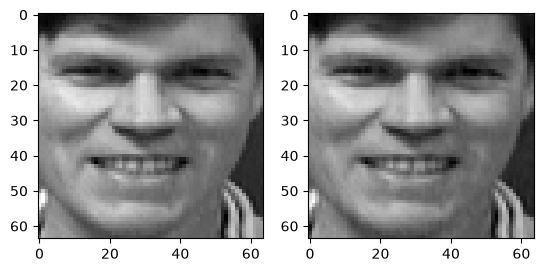

In [42]:
nb_components = 300
np.random.seed(67)
n = np.random.randint(400)
Im = images[n]
pca = PCA(n_components=nb_components)
pca.fit(X)

recons = pca.inverse_transform(pca.transform(Im.reshape((1,4096))))

#calcul de la MSE entre la photo originale et la reconstruction :
mse = np.mean((recons - Im.reshape((1,4096)))**2)
print(mse)

fig, axes = plt.subplots(1,2)
axes[0].imshow(Im, cmap = "gray")
axes[1].imshow(recons.reshape((64,64)), cmap= "gray")


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Avec 300 composantes principales la MSE est très faible, donc on peut considérer la reconstruction de très bonne qualité, ce qui se voit à l'oeil.
</div>

**Q6.** For the same image, display with subplots how the reconstruction evolves while keeping only 10, 20, 30... Up to 300 components.

What is the minimal number of components for which you consider the reconstruction to be acceptable ?

Conclude about the usefulness of this method.

0 comp (moyenne) : 0.03179125487804413
5 comp : 0.011532586067914963
10 comp : 0.007590750698000193
20 comp : 0.004804863128811121
30 comp : 0.003333290107548237
50 comp : 0.002588364528492093
75 comp : 0.0017057063523679972
100 comp : 0.0011900480603799224
125 comp : 0.0008676573052071035
150 comp : 0.0006485938793048263
300 comp : 0.00011509079195093364


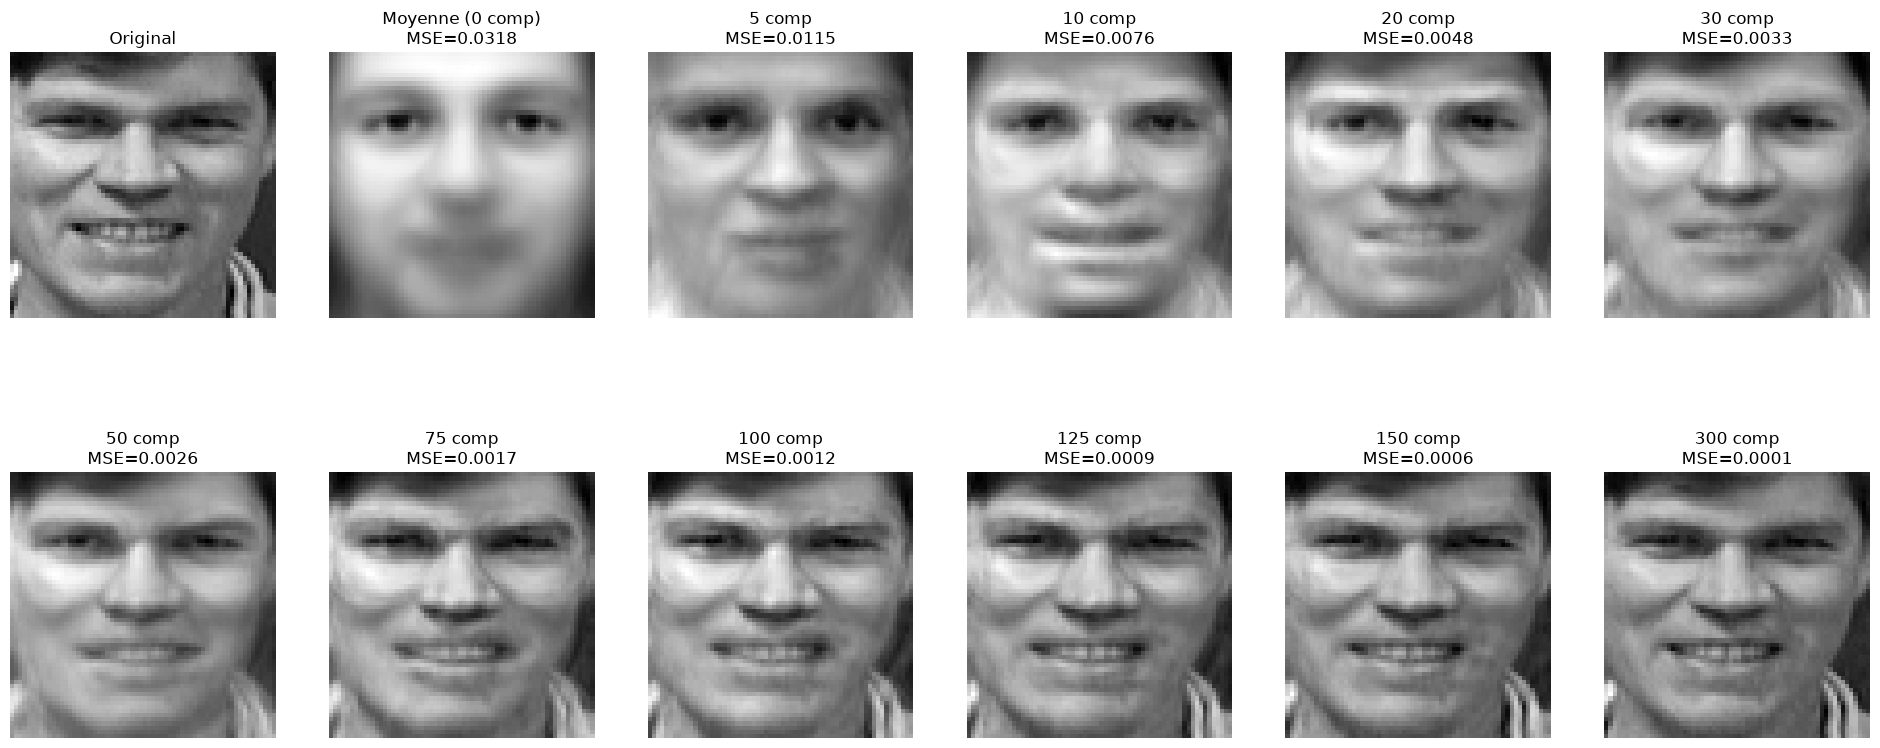

In [55]:
# effet du nombre de composantes et observation de la reconstruction à partir de la moyenne :
fig, axes = plt.subplots(2, 6, figsize=(24, 10))
axes = axes.ravel()
axes[0].imshow(Im, cmap="gray")
axes[0].set_title("Original")

moyenne = X.mean(axis=0)
mse = np.mean((moyenne - Im.reshape(4096)) ** 2)
print(f"0 comp (moyenne) : {mse}")
axes[1].imshow(moyenne.reshape(64, 64), cmap="gray")
axes[1].set_title(f"Moyenne (0 comp)\nMSE={mse:.4f}")

for ax, k in zip(axes[2:], [5, 10, 20, 30, 50, 75, 100, 125, 150, 300]):
    p = PCA(n_components=k).fit(X)
    r = p.inverse_transform(p.transform(Im.reshape(1, 4096)))
    mse = np.mean((r - Im.reshape((1, 4096))) ** 2)
    print(f"{k} comp : {mse}")
    ax.imshow(r.reshape(64, 64), cmap="gray")
    ax.set_title(f"{k} comp\nMSE={mse:.4f}")
for ax in axes:
    ax.axis("off")


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
La reconstruction ne semble être satisfaisante que lorsque qu'on atteint un nombre de composantes qui expliquent en cumulé une proportion significative de la variance du dataset. Ici 123 composantes expliquent 95% de la variance, et on constate que c'est environ autour de 100 composantes qu'on obtient une reconstruction plutôt satisfaisante.
</div>

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
L'utilité de la PCA est donc bien mise en évidence ici : Dans cet exemple, on obtient une reconstruction très proche de l'original pour toute image du dataset à partir d'un nombre de PC de l'ordre du quart du nombre de features original. On réduit donc grandement la dimensionalité du dataset tout en conservant ses caractéristiques principales, ce qui peut être très utile pour de futures apprentissages dessus.
</div>